# Lab 5 — TRIK Motor Identification: M3 and M4

**Self-contained notebook:** All **eight original encoder recordings** are embedded in this notebook. No `.txt`, `.csv`, or image files are required. Run the cells from top to bottom to reproduce the tables and figures.

**Experiment:** PWM = 30%, 50%, 70%, 100% for each motor; 100 encoder samples per test, nominal interval 20 ms. The first encoder sample is assigned $t=0$. Encoder units have not been converted to radians. Timing is nominal, not measured.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import json, zlib, base64

DT = 0.020  # seconds, nominal loop delay
PWMS = [30, 50, 70, 100]
MOTORS = ['M3', 'M4']
# Compressed, lossless copies of the eight measured position arrays:
EMBEDDED_DATA = "eJxll1uO5TYMRLfSyHd/6P3IHrKCYJCFBNl7dA5l3w4CTN+xZVsSWaxi6e/f/qh/1fTb719/pu+v869+f43vr5zP3/m/lPO3z+j8/mr9+6u38/iMzfN8nf/3+cuJn3ye5MJP5fu2mODMl+eZMa/zbd5nkpI2szJtPWOlMdYZY8rCe2Wfb2s+r9Rybmtl/c7tGOyEW9Zt6dy2ctZolVv215iqsWRbZ+ae2HM+Y71Wdn++6Oyq80pf53akczsyYZfzxWjcGuY42xgEOfZ5b7LxycYnAc5+3pvjvDfn+WyyoZUmWSE19TxY5GCRrTXPNtY6E2w2tNnQZkOb8Dev7Hkm3ZuEpUQWU578VoBIhJYTseVkPhPR5fMSv5mnGZgOCmLRHRmOLN7PhJALSc2leN3Sr+8v0O8P+sQGfucqX9jJHAmpREwM7szJeZPturfB2OTpbnzObCxT2M/Flwf7vFdJU6VUKk9rt77AnE024m5VLIFxgi/rdj7rxSKsL4w82B0EAYoNDXI6QOaCJ25AxmqT1S5kYMRni88uWoMgG0DlFygg62J03ttmPiURKZZ/E7Vubqbj25yThYOLSLVAxPHlOFV+EGG8UAu5kOlchuMr8sv8lV3kWsVGZKs1UElmbon3m5g2EpPbmBKQN3tiRAbkLjE7tZ1NXO5WxZC6w0obbd+qmE9VWG4AC3JAQ9phwcmUBRkRuImX8zwgwJL5qespAvFHXCrLBavJqrE0wAguB/RnX23LYHjL9jtLX9Q3qO+HslTgILMTQk8qOAC3diHBgleryExqmRJZZGkjJJsMXj4uYDY2E3cBtsbTkmCmNeTuZF1oBdikFyr10Ewgm2QTkmLpVAGr0rUKeUX6HjilaLMgWvdasNsWNqHqVTjdTzfVilgeJSAUBkttUMp5El+eFuJUmKfSMI1xie4S/uWKKyTb/WwLdKNnefehio9bIocFt0bAF+5SF3AkxMbN3w5QkpKAvHfEBQZWOFbZVgXvCnq3Bs6EDXyC+WSy81nns5EUa5BnQ7J8ktTJLoPg0MfAFlUTIsxUmwTu5h4VXAmcpa55S9Ivme0IIWLI0/5mnq+AmqsikaoksKYPpqK8gpzzB5pbWo4PjtZVn0UqimPpQUJ+lZKp2k5raUrd6cz2moNaNFdxjB5r/WzFYlshClZJrFis5GKMJYVSK/XGWKRtKcm+XwMvr5ftOkllu3Zl5kNrRlq2jzdGlJ5irZ70MIMtt/SZrZn2H6txZu1XXNrtOdQCsJfoOwTGlDRHmdofwQndVCRD7cyhCbOmCZxdJ7tZf9pRKBFrG4GVuWxMWIuk8UDoiP52J/oU5K6WLJRpSbFCosCrUWKNSdtQtvp1Hw1MO2rX0cde7V3WMg9gfUeYooEBaOiZpU0+ByUWrWxa6euRN1C+ZoSaR8+mqkz4U0bY3sjVytqSje7BAyIK8SOiRZquLUH8eG+zeLQ83tu8t6P3S4CUw/bZGqqYSJLHoYRQ1gv56y/yB2/L5GLdaOYX5/1YSjFWIuVRf+G14NeLLBPRMcJIBqh6SABklosnV0AUUK70ug2gVLuIuXVVjCt42gG6s0Znjc4afdS3A9UHtqL5mC9iOkee0gMnlSKDZ6uvA7ErkX/iCIgg84L7izUWayzW2ElggIP63TiNzQQPJvXTqhTqpICk4bVcSEpyFresmDxO8SNu2XZQop8rfaWG0Hk9vNa7FHlYRVKPnqtSVvv4tDObnVQ5TW3eWvifq5Bx92xBXig3N2zDDJujSNq7HlaHv1wv7P3SWMNUS35PDfvhbYDdXn+RXmspR0GXyr8Qg/2SlO1BN1xlf/tNfk1GejEFYhBf+JXoPPi1FV4J/Ci3jbjsnl6nEYZyfCh1O1HQSLMo7YIQua4fwAVPhCxOYNdKCpla+LiO+QOsOKaZXf1Mc/7m/DbfLBOyFux4jzCR9in52O19Ktihpa4jhwOxc8XhT88zVnQxf/VLkiBry7JKdXpZuuXxcRRXIHQU+Qp/OAq9jPpub6ISWr9Hx2st0XJafmXsp6OoL+AgbJcZ7wnC4x9GZCBDbnlWweXwAA4hp2Rgkf7lCZimEYc5imDruJIeL4nFFUXH75FAWuUhAVcUutiNwEsSZdGx+NWs1x9Kq2v0xSucocmxfF9HIQpWlLJ0HIUuQrmYIjUdt3CzwWXPQsdRDGVWL2EsnoJeRzF0FNFfdRdDd4HolqwmKy8l6zTiTBhQFXZ+erFOw/HqeNUneAw8J9PqydHrHuIefVtfoTPpffz651+L4RJQ"
data = json.loads(zlib.decompress(base64.b64decode(EMBEDDED_DATA)).decode())
measurements = {(m,p): np.asarray(data[f'{m}_{p}'], dtype=float) for m in MOTORS for p in PWMS}
assert all(len(y) == 100 for y in measurements.values())
print('Loaded', len(measurements), 'embedded experiments; total samples:', sum(map(len,measurements.values())))

Loaded 8 embedded experiments; total samples: 800


## 1. Inspect the measured data

These are the actual encoder readings recorded by TRIK Studio. The table shows the initial and final position and checks whether position increased over the test.

In [2]:
overview = pd.DataFrame([
    {'motor':m,'PWM (%)':p,'samples':len(y),'start':y[0],'final':y[-1],
     'all_increments_nonnegative':bool(np.all(np.diff(y)>=0))}
    for (m,p),y in measurements.items()])
display(overview)

,motor,PWM (%),samples,start,final,all_increments_nonnegative
0,M3,30,100,0.0,1240.0,True
1,M3,50,100,0.0,1649.0,True
2,M3,70,100,0.0,1976.0,True
3,M3,100,100,0.0,2571.0,True
4,M4,30,100,0.0,1083.0,True
5,M4,50,100,0.0,1417.0,True
6,M4,70,100,0.0,1800.0,True
7,M4,100,100,0.0,2556.0,True


## 2. Motor model and fitting

Assume a first-order speed response to a PWM step from rest:

$$\omega(t)=\omega_{ss}(1-e^{-t/T_m})$$

Integrating speed gives the encoder-position model:

$$\theta(t)=\theta_0+\omega_{ss}\left[t-T_m(1-e^{-t/T_m})\right].$$

We fit **position** rather than differentiating noisy/quantized encoder data. SciPy robust least squares estimates steady speed, time constant $T_m$, and an offset. Values are estimates conditioned on the assumed 20 ms sample spacing.

In [3]:
def position_model(t, omega_ss, tau, offset):
    return offset + omega_ss*(t - tau*(-np.expm1(-t/tau)))

fits = {}
rows = []
for (motor, pwm), theta in measurements.items():
    t = np.arange(len(theta))*DT
    tail_speed = np.median(np.diff(theta)[-40:])/DT
    result = least_squares(
        lambda params: position_model(t,*params)-theta,
        x0=[tail_speed,0.15,0],
        bounds=([0,0.005,-80],[10000,2,80]),
        loss='soft_l1',f_scale=5
    )
    omega, tau, offset = result.x
    predicted = position_model(t,*result.x)
    r2 = 1-np.sum((theta-predicted)**2)/np.sum((theta-theta.mean())**2)
    fits[motor,pwm] = {'t':t,'theta':theta,'predicted':predicted,'omega':omega,'tau':tau}
    rows.append({'motor':motor,'PWM (%)':pwm,'tail speed (units/s)':tail_speed,
                 'fitted speed (units/s)':omega,'T_m (s)':tau,
                 'fit offset (units)':offset,'position R²':r2})
summary = pd.DataFrame(rows)
display(summary.round(4))

,motor,PWM (%),tail speed (units/s),fitted speed (units/s),T_m (s),fit offset (units),position R²
0,M3,30,700.0,696.3087,0.2032,1.9265,1.0
1,M3,50,900.0,890.4123,0.1352,1.9184,1.0
2,M3,70,1050.0,1045.4132,0.0890,0.1980,1.0
3,M3,100,1300.0,1316.6151,0.0278,0.2623,1.0
4,M4,30,600.0,597.5009,0.1677,-0.2283,1.0
5,M4,50,750.0,762.2171,0.1248,1.6262,1.0
6,M4,70,950.0,947.2664,0.0838,3.3091,1.0
7,M4,100,1300.0,1310.9986,0.0245,-1.4497,1.0


## 3. Measured encoder positions and interval speeds

The interval speed is $[\theta_i-\theta_{i-1}]/0.020$ in encoder units/s. Spikes can arise from encoder quantization, variable program timing, or other measurement effects.

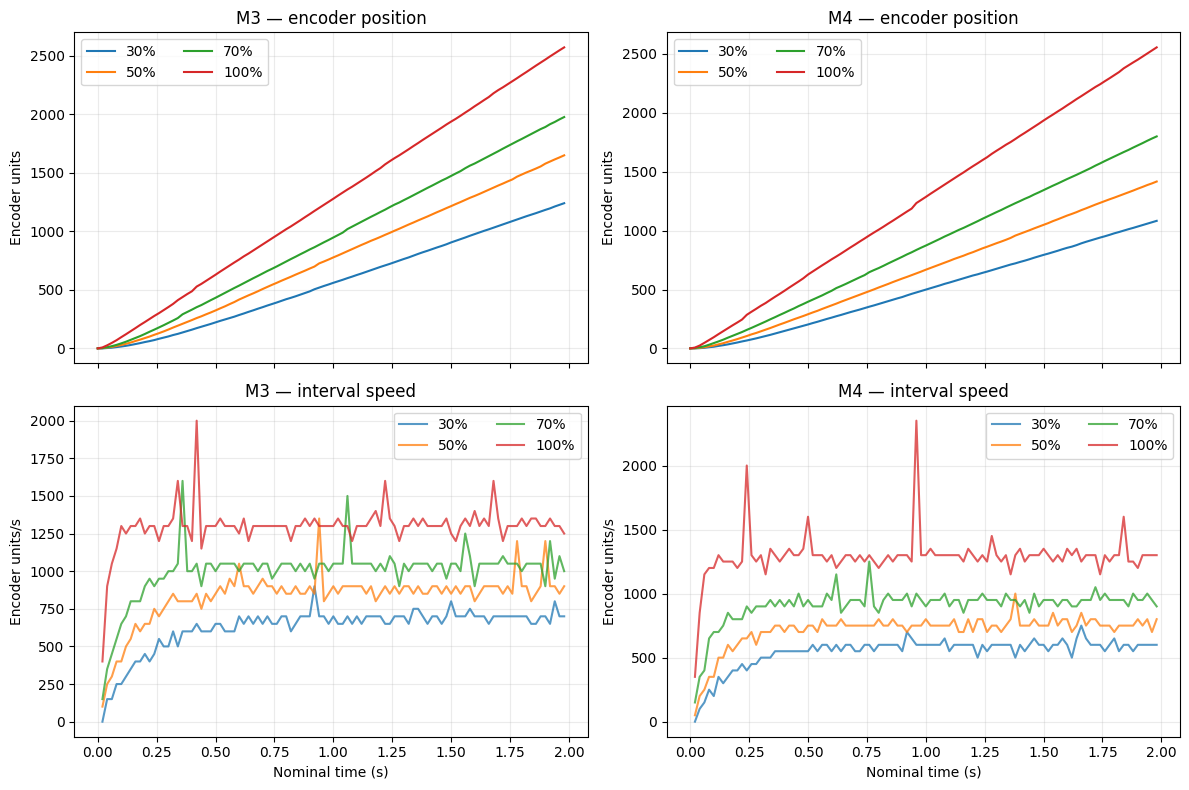

In [4]:
fig, axes = plt.subplots(2,2,figsize=(12,8),sharex='col')
for j,m in enumerate(MOTORS):
    for pwm in PWMS:
        f=fits[m,pwm]
        axes[0,j].plot(f['t'],f['theta'],label=f'{pwm}%')
        axes[1,j].plot(f['t'][1:],np.diff(f['theta'])/DT,alpha=.75,label=f'{pwm}%')
    axes[0,j].set_title(f'{m} — encoder position')
    axes[1,j].set_title(f'{m} — interval speed')
    axes[0,j].set_ylabel('Encoder units')
    axes[1,j].set_ylabel('Encoder units/s')
    axes[1,j].set_xlabel('Nominal time (s)')
    for ax in axes[:,j]: ax.grid(alpha=.25); ax.legend(ncol=2)
fig.tight_layout(); plt.show()

## 4. Measured versus simulated first-order response

Solid lines show fitted position; dots show measured encoder position. A close fit does not prove the underlying motor has exactly first-order dynamics.

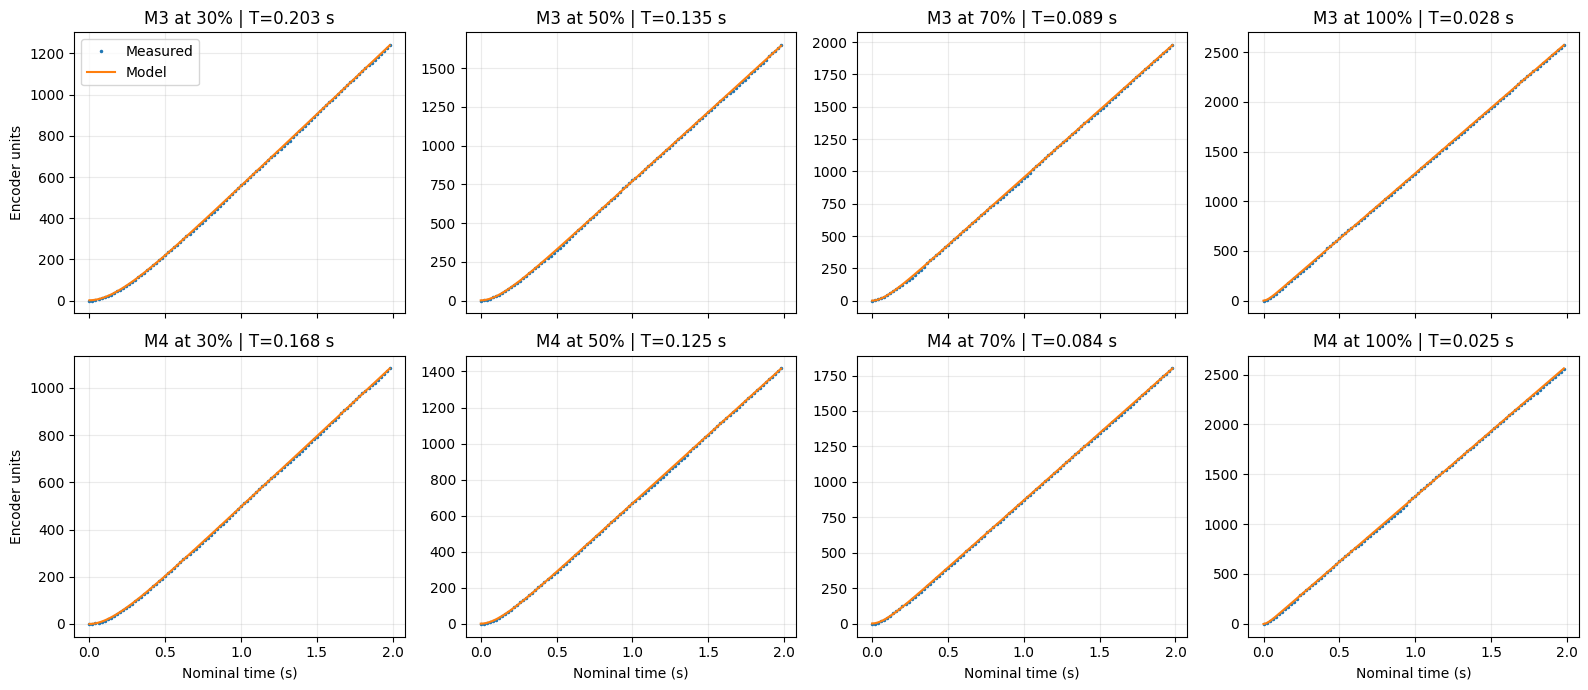

In [5]:
fig, axes=plt.subplots(2,4,figsize=(16,7),sharex=True)
for i,m in enumerate(MOTORS):
    for j,pwm in enumerate(PWMS):
        f=fits[m,pwm]; ax=axes[i,j]
        ax.plot(f['t'],f['theta'],'.',ms=3,label='Measured')
        ax.plot(f['t'],f['predicted'],'-',label='Model')
        ax.set_title(f'{m} at {pwm}% | T={f["tau"]:.3f} s')
        ax.grid(alpha=.25)
        if j==0: ax.set_ylabel('Encoder units')
        if i==1: ax.set_xlabel('Nominal time (s)')
axes[0,0].legend(); fig.tight_layout(); plt.show()

## 5. PWM-speed and PWM-time constant comparisons

This is a **selected positive-PWM** comparison, not a full bidirectional PWM sweep. The speed graph uses the median of the last 40 encoder increments as a simple late-time estimate.

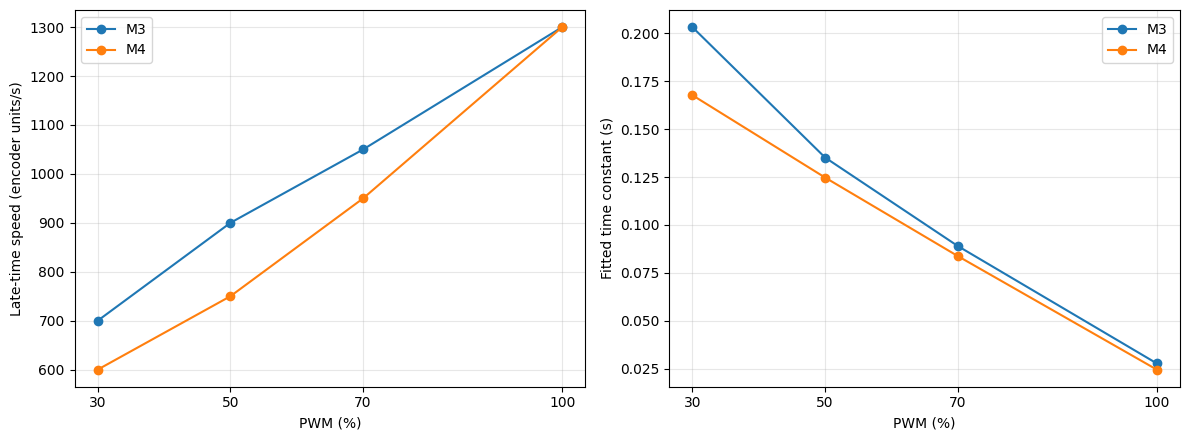

In [6]:
fig, axes=plt.subplots(1,2,figsize=(12,4.5))
for m in MOTORS:
    s=summary[summary.motor==m]
    axes[0].plot(s['PWM (%)'],s['tail speed (units/s)'],'o-',label=m)
    axes[1].plot(s['PWM (%)'],s['T_m (s)'],'o-',label=m)
axes[0].set_ylabel('Late-time speed (encoder units/s)')
axes[1].set_ylabel('Fitted time constant (s)')
for ax in axes:
    ax.set_xlabel('PWM (%)'); ax.set_xticks(PWMS); ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); plt.show()

## 6. M3 versus M4: measured differences

In [7]:
wide=overview.pivot(index='PWM (%)',columns='motor',values='final')
wide['M3 minus M4 (encoder units)']=wide['M3']-wide['M4']
wide['M3 excess over M4 (%)']=100*(wide['M3']/wide['M4']-1)
display(wide.round(2))

motor,M3,M4,M3 minus M4 (encoder units),M3 excess over M4 (%)
PWM (%),,,,
30,1240.0,1083.0,157.0,14.50
50,1649.0,1417.0,232.0,16.37
70,1976.0,1800.0,176.0,9.78
100,2571.0,2556.0,15.0,0.59


## 7. Back-EMF, nonlinearity, and odometry discussion

**Back-EMF $k_e$:** A physical back-EMF constant cannot be identified reliably from encoder positions and commanded PWM alone. It would require at least calibrated angular speed (rad/s) and information about actual motor terminal voltage and/or electrical parameters, including the voltage lost across winding resistance under load. No such voltage/current measurements were recorded; therefore this notebook does **not** invent $k_e$.

**Nonlinearity and dead zone:** Speeds increase with PWM over the four tested positive commands, but four positive levels cannot establish the zero-speed dead zone, reverse-direction symmetry, saturation beyond tested conditions, or a complete $-100\%$ to $+100\%$ curve.

**Odometry:** If M3 and M4 drive opposite wheels, different wheel speeds under the same command could make the robot turn or drift. Quantitative odometry error cannot be calculated because no wheel radius, wheelbase, calibrated encoder-to-angle conversion, ground-truth trajectory, or driving-path data were collected.

**Timing limitation:** The 20 ms delay is not a measured timestamp. File writes and control-loop overhead may make the real sampling interval longer or irregular. Consequently, fitted speeds and $T_m$ may be biased. The time constants also change with PWM, suggesting that the simple first-order model and operating-point assumptions have limitations.

## 8. Conclusions

- Eight usable step-response datasets were collected (two motors × four positive PWM levels).
- M3 accumulated more encoder units than M4 at 30%, 50%, and 70%; their 100% results were nearly equal.
- Both motors show higher late-time speed at larger positive PWM values.
- A first-order position response can be fitted to each recording to estimate nominal steady speed and $T_m$.
- The full negative-to-positive PWM sweep, defensible physical $k_e$, and quantitative odometry validation remain outside the collected data.

## 9. Optional: export the data and fitted parameters

The notebook already contains everything needed. Run this cell only if you want separate CSV files.

In [8]:
all_rows=[]
for (m,p),f in fits.items():
    for i,(t,y,pred) in enumerate(zip(f['t'],f['theta'],f['predicted'])):
        all_rows.append({'motor':m,'PWM (%)':p,'sample':i,'nominal_time_s':t,
                         'encoder_units':y,'fitted_encoder_units':pred})
all_data=pd.DataFrame(all_rows)
# Uncomment to export:
# all_data.to_csv('Lab5_all_measurements.csv',index=False)
# summary.to_csv('Lab5_motor_parameters.csv',index=False)
print('Embedded samples:',len(all_data),'| fitted parameter rows:',len(summary))

Embedded samples: 800 | fitted parameter rows: 8
